<a href="https://colab.research.google.com/github/PDM-15/AML-2026/blob/master/AML_Lab7/ML_Lab7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Bias Variance tradeoff

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

np.random.seed(42)        #Genearate non linear reproducible data

X = np.linspace(0, 10, 40).reshape(-1,1)

y = 2 + 0.5 * X[:,0] ** 2 + np.random.normal(0, 5, 40)          #generate random noise - medium range

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state = 42)

degrees = [1, 2, 10]

for degree in degrees:
    model = make_pipeline(PolynomialFeatures(degree = degree, include_bias = False), LinearRegression())        #finding lin reg for each degree
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_mse = mean_squared_error(y_train, train_pred)
    test_mse = mean_squared_error(y_test, test_pred)

    print(f"Polynomial degree: {degree}")
    print(f"Training error: {train_mse:.2f}")
    print(f"Testing error: {test_mse:.2f}\n")

Polynomial degree: 1
Training error: 42.90
Testing error: 42.99

Polynomial degree: 2
Training error: 20.44
Testing error: 19.79

Polynomial degree: 10
Training error: 12.89
Testing error: 95.21



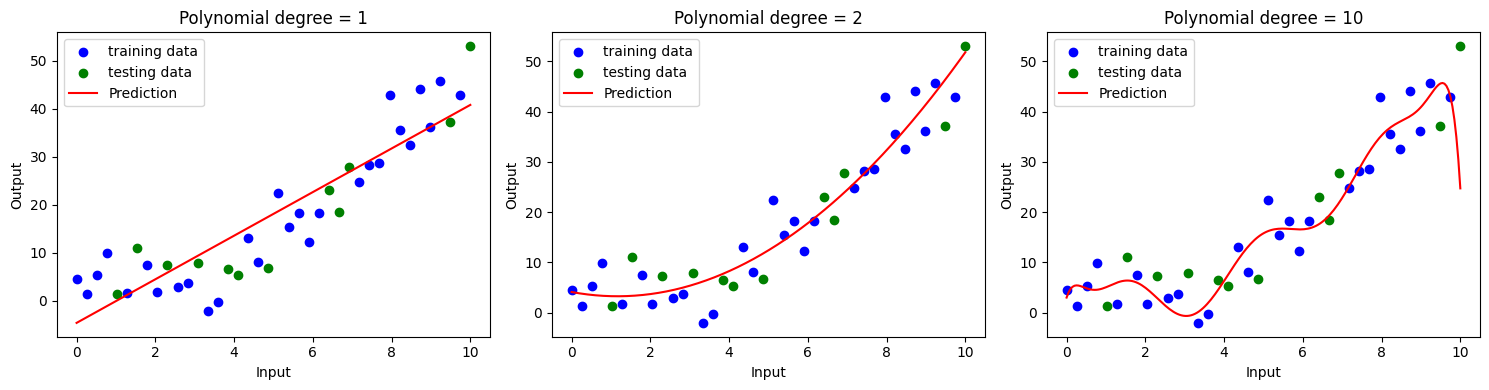

In [ ]:
X_plot = np.linspace(0, 10, 200).reshape(-1,1)

plt.figure(figsize=(15, 4))

for index,degree in enumerate(degrees):
    model = make_pipeline(PolynomialFeatures(degree = degree, include_bias = False), LinearRegression())

    model.fit(X_train, y_train)
    y_plot = model.predict(X_plot)

    plt.subplot(1, 3, index + 1)
    plt.scatter(X_train, y_train, color = 'blue', label = "training data")
    plt.scatter(X_test, y_test, color = 'green', label = "testing data")
    plt.plot(X_plot, y_plot, color = 'red', label = "Prediction")

    plt.title(f"Polynomial degree = {degree}")
    plt.xlabel("Input")
    plt.ylabel("Output")
    plt.legend()

plt.tight_layout()
plt.show()

Cross Validation and model selection

In [ ]:
from sklearn.model_selection import cross_val_score

for degree in range(1,11):
    model = make_pipeline(PolynomialFeatures(degree = degree, include_bias = False), LinearRegression())

    scores = cross_val_score(model, X, y, cv = 5, scoring = 'neg_mean_squared_error')

    mse = -scores.mean()

    print(f"Polynomial degree: {degree} : Cross-validation MSE: {mse:.2f}")

Polynomial degree: 1 : Cross-validation MSE: 110.69
Polynomial degree: 2 : Cross-validation MSE: 44.22
Polynomial degree: 3 : Cross-validation MSE: 71.23
Polynomial degree: 4 : Cross-validation MSE: 82.46
Polynomial degree: 5 : Cross-validation MSE: 1348.27
Polynomial degree: 6 : Cross-validation MSE: 11392.13
Polynomial degree: 7 : Cross-validation MSE: 53226.76
Polynomial degree: 8 : Cross-validation MSE: 99956.80
Polynomial degree: 9 : Cross-validation MSE: 1196598.07
Polynomial degree: 10 : Cross-validation MSE: 11490574.52


Feature selection

In [ ]:
import pandas as pd
from sklearn.feature_selection import VarianceThreshold

X = pd.DataFrame({"constant_feature": [1,1,1,1,1], "almost_constant" : [0,0,0,0,1], "useful_feature" : [10,20,30,40,50]})

selector = VarianceThreshold(threshold = 0.0)
X_selected = selector.fit_transform(X)

selected_columns = X.columns[selector.get_support()]

print("Selected Features:", list(selected_columns))

Selected Features: ['almost_constant', 'useful_feature']


In [ ]:
import pandas as pd
from sklearn.feature_selection import VarianceThreshold

X = pd.DataFrame({"constant_feature": [1,1,1,1,1], "almost_constant" : [0,0,0,0,1], "useful_feature" : [10,20,30,40,50]})

selector = VarianceThreshold(threshold = 0.17)
X_selected = selector.fit_transform(X)

selected_columns = X.columns[selector.get_support()]

print("Selected Features:", list(selected_columns))

Selected Features: ['useful_feature']


Correlation among features

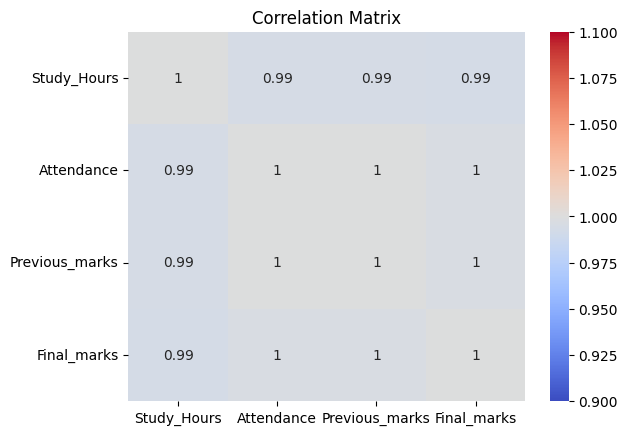

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

data = pd.DataFrame({"Study_Hours": [1,2,3,4,5,6], "Attendance" : [50, 55, 65, 70, 80, 90], "Previous_marks": [35, 40, 50, 55, 65, 75], "Final_marks" : [38, 45, 52, 60, 70, 82]})

correlation_matrix = data.corr(numeric_only=True)

sns.heatmap(correlation_matrix, annot = True, cmap = 'coolwarm', vmin=1, vmax=1)

plt.title("Correlation Matrix")
plt.show()

ChiSquare Test

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import MinMaxScaler

data = load_breast_cancer()
X = data.data
y = data.target

X_non_negative = MinMaxScaler().fit_transform(X)

selector = SelectKBest(score_func = chi2, k = 5)
X_selected = selector.fit_transform(X_non_negative, y)

selected_features = data.feature_names[selector.get_support()]

print("Selected Features:", selected_features)

Selected Features: ['mean concavity' 'mean concave points' 'worst perimeter' 'worst area'
 'worst concave points']


In [ ]:
#Univariate Feature Selection

from sklearn.datasets import load_iris

iris = load_iris()
X = iris.data
y = iris.target

X_select = SelectKBest(chi2, k =3).fit_transform(X,y)
X_select



array([[5.1, 1.4, 0.2],
       [4.9, 1.4, 0.2],
       [4.7, 1.3, 0.2],
       [4.6, 1.5, 0.2],
       [5. , 1.4, 0.2],
       [5.4, 1.7, 0.4],
       [4.6, 1.4, 0.3],
       [5. , 1.5, 0.2],
       [4.4, 1.4, 0.2],
       [4.9, 1.5, 0.1],
       [5.4, 1.5, 0.2],
       [4.8, 1.6, 0.2],
       [4.8, 1.4, 0.1],
       [4.3, 1.1, 0.1],
       [5.8, 1.2, 0.2],
       [5.7, 1.5, 0.4],
       [5.4, 1.3, 0.4],
       [5.1, 1.4, 0.3],
       [5.7, 1.7, 0.3],
       [5.1, 1.5, 0.3],
       [5.4, 1.7, 0.2],
       [5.1, 1.5, 0.4],
       [4.6, 1. , 0.2],
       [5.1, 1.7, 0.5],
       [4.8, 1.9, 0.2],
       [5. , 1.6, 0.2],
       [5. , 1.6, 0.4],
       [5.2, 1.5, 0.2],
       [5.2, 1.4, 0.2],
       [4.7, 1.6, 0.2],
       [4.8, 1.6, 0.2],
       [5.4, 1.5, 0.4],
       [5.2, 1.5, 0.1],
       [5.5, 1.4, 0.2],
       [4.9, 1.5, 0.2],
       [5. , 1.2, 0.2],
       [5.5, 1.3, 0.2],
       [4.9, 1.4, 0.1],
       [4.4, 1.3, 0.2],
       [5.1, 1.5, 0.2],
       [5. , 1.3, 0.3],
       [4.5, 1.3

ANOVA F-test

In [ ]:
from sklearn.datasets import load_iris
from sklearn.feature_selection import SelectKBest, f_classif

iris = load_iris()
X = iris.data
y = iris.target

selector = SelectKBest(score_func = f_classif, k =2)
X_selected = selector.fit_transform(X,y)

selected_features = np.array(iris.feature_names)[selector.get_support()]

print("Selected Features:", selected_features)


Selected Features: ['petal length (cm)' 'petal width (cm)']
